In [1]:
!pip install onnx onnxruntime torch torchvision matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.9/8.9 MB 23.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 82.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [onnx]


In [2]:
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
import numpy as np
import os

print("PyTorch Version:", torch.__version__)

PyTorch Version: 2.14.1+cu130


In [3]:
class DigitModel(nn.Module):

    def __init__(self):
        super(DigitModel, self).__init__()

        self.flatten = nn.Flatten()

        self.fc1 = nn.Linear(784, 128)
        self.relu = nn.ReLU()

        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):
        x = self.flatten(x)
        x = self.relu(self.fc1(x))
        x = self.fc2(x)
        return x

model = DigitModel()

print(model)

DigitModel(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (fc1): Linear(in_features=784, out_features=128, bias=True)
  (relu): ReLU()
  (fc2): Linear(in_features=128, out_features=10, bias=True)
)


In [4]:
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

transform = transforms.ToTensor()

train_data = datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

train_loader = DataLoader(
    train_data,
    batch_size=64,
    shuffle=True
)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

epochs = 3
loss_values = []

for epoch in range(epochs):

    total_loss = 0

    for images, labels in train_loader:

        outputs = model(images)

        loss = criterion(outputs, labels)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    avg_loss = total_loss / len(train_loader)
    loss_values.append(avg_loss)

    print("Epoch:", epoch + 1,
          "Loss:", round(avg_loss, 4))

print("Training completed")

100%|██████████| 9.91M/9.91M [00:00<00:00, 20.8MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 504kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.57MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 7.10MB/s]


Epoch: 1 Loss: 0.3451
Epoch: 2 Loss: 0.1521
Epoch: 3 Loss: 0.1052
Training completed


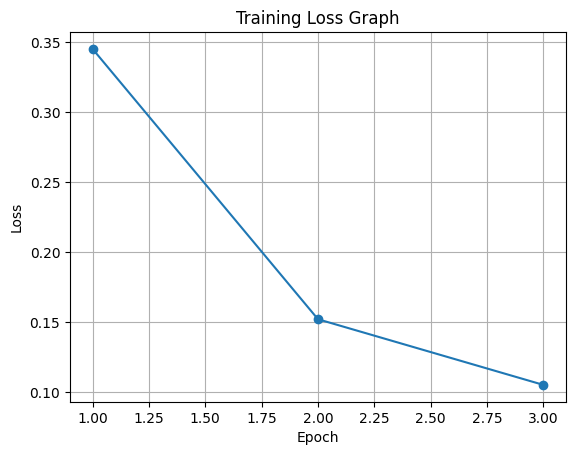

In [5]:
plt.plot(
    range(1, epochs + 1),
    loss_values,
    marker="o"
)

plt.title("Training Loss Graph")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.grid(True)

plt.show()

In [6]:
os.makedirs("artifacts", exist_ok=True)

torch.save(
    model.state_dict(),
    "artifacts/model_checkpoint.pth"
)

print("Checkpoint saved successfully")

Checkpoint saved successfully


In [7]:
loaded_model = DigitModel()

loaded_model.load_state_dict(
    torch.load(
        "artifacts/model_checkpoint.pth",
        map_location="cpu",
        weights_only=True
    )
)

loaded_model.eval()

sample = torch.randn(1, 1, 28, 28)

with torch.no_grad():
    prediction = loaded_model(sample)

print("Output shape:", prediction.shape)

Output shape: torch.Size([1, 10])


In [8]:
model.eval()

dummy_input = torch.randn(1, 1, 28, 28)

torch.onnx.export(
    model,
    dummy_input,
    "artifacts/model.onnx",
    input_names=["input"],
    output_names=["output"],
    opset_version=17,
    dynamo=False
)

print("ONNX model exported successfully")

ONNX model exported successfully


/tmp/ipykernel_418/583404331.py:5: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(


In [9]:
import onnx

onnx_model = onnx.load("artifacts/model.onnx")

onnx.checker.check_model(onnx_model)

print("ONNX graph is valid")

print("Graph nodes:")

for node in onnx_model.graph.node:
    print(node.op_type)

ONNX graph is valid
Graph nodes:
Flatten
Gemm
Relu
Gemm


In [10]:
import onnxruntime as ort

session = ort.InferenceSession(
    "artifacts/model.onnx",
    providers=["CPUExecutionProvider"]
)

input_name = session.get_inputs()[0].name

sample = np.random.randn(
    1, 1, 28, 28
).astype(np.float32)

result = session.run(
    None,
    {input_name: sample}
)

print("ONNX output shape:", result[0].shape)

ONNX output shape: (1, 10)


In [12]:
!trtexec \
  --onnx=artifacts/model.onnx \
  --saveEngine=artifacts/model.engine \
  --fp16

/bin/bash: line 1: trtexec: command not found
